# ПР-5. Классификатор и анализ метрик при сильном дисбалансе
Цель: предсказать просрочку по кредиту (default), сравнить базовую модель с методами борьбы с дисбалансом классов (class_weight, undersampling, SMOTE) при одинаковой схеме валидации.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

from src.transformers import CreditCleaner

df = pd.read_csv("../data/cs-training.csv", index_col=0)

df = df.rename(columns={
    "SeriousDlqin2yrs": "default",
    "RevolvingUtilizationOfUnsecuredLines": "utilization",
    "NumberOfTime30-59DaysPastDueNotWorse": "late_30_59",
    "DebtRatio": "debt_ratio",
    "MonthlyIncome": "income",
    "NumberOfOpenCreditLinesAndLoans": "open_credits",
    "NumberOfTimes90DaysLate": "late_90",
    "NumberRealEstateLoansOrLines": "real_estate",
    "NumberOfTime30-59DaysPastDueNotWorse": "late_30_59",
    "NumberOfTime60-89DaysPastDueNotWorse": "late_60_89",
    "NumberOfDependents": "dependents",
})
df.shape

(150000, 11)

In [2]:
print("Доля просрочек:", df["default"].mean())
print("Соотношение классов 0 : 1 =", round((df["default"] == 0).sum() / (df["default"] == 1).sum(), 1), ": 1")

Доля просрочек: 0.06684
Соотношение классов 0 : 1 = 14.0 : 1


## Дисбаланс классов
Просрочку допустили 6,68% клиентов, соотношение классов 14 : 1. Это соответствует требованию задания (1:10 и сильнее). При таком дисбалансе accuracy нельзя считать главной метрикой: модель, которая всегда отвечает «просрочки не будет», была бы права примерно в 93% случаев и при этом не нашла бы ни одного должника.

In [3]:
X = df.drop(columns="default")
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print("Доля просрочек train / test:", y_train.mean(), y_test.mean())

(120000, 10) (30000, 10)
Доля просрочек train / test: 0.06684166666666666 0.06683333333333333


Данные разбиты на обучающую (120 000 клиентов) и тестовую (30 000 клиентов) части в пропорции 80/20 с сохранением долей классов (stratify): доля просрочек в обеих частях 6,68%. Тестовая выборка используется только для итоговой оценки.

In [4]:
def make_pipe(sampler=None, class_weight=None):
    steps = [
        ("cleaner", CreditCleaner()),
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
    if sampler is not None:
        steps.append(("sampler", sampler))   # применяется только при обучении
    steps.append(("model", LogisticRegression(max_iter=1000, class_weight=class_weight)))
    return ImbPipeline(steps)

models = {
    "baseline":     make_pipe(),
    "class_weight": make_pipe(class_weight="balanced"),
    "undersample":  make_pipe(sampler=RandomUnderSampler(random_state=42)),
    "SMOTE":        make_pipe(sampler=SMOTE(random_state=42)),
}

## Сравниваемые варианты
- **baseline**: логистическая регрессия без коррекции дисбаланса (точка отсчёта).
- **class_weight**: ошибки на редком классе штрафуются сильнее (веса классов обратно пропорциональны их частоте).
- **undersample**: случайно удаляются примеры большого класса, пока классы не сравняются (только на обучающей части).
- **SMOTE**: для редкого класса создаются синтетические примеры между соседними реальными (только на обучающей части).

Во всех вариантах предобработка (пайплайн из ПР-3) и модель одинаковые, меняется только способ борьбы с дисбалансом. Пересэмплирование выполняется внутри пайплайна только на обучающей части каждого фолда, поэтому утечки данных нет. Схема проверки одинакова для всех: 5-кратная кросс-валидация, повторённая 3 раза (15 проверок на метод).

In [5]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

cv_results = {}
for name, pipe in models.items():
    cv_results[name] = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    print("готово:", name)

готово: baseline
готово: class_weight
готово: undersample
готово: SMOTE


In [6]:
rows = []
for name, res in cv_results.items():
    row = {"метод": name}
    for m in scoring:
        vals = res[f"test_{m}"]
        row[m] = f"{vals.mean():.3f} ± {vals.std():.3f}"
    rows.append(row)
summary = pd.DataFrame(rows).set_index("метод")
summary

,roc_auc,pr_auc,precision,recall,f1
метод,,,,,
baseline,0.849 ± 0.004,0.373 ± 0.008,0.598 ± 0.012,0.164 ± 0.007,0.257 ± 0.009
class_weight,0.854 ± 0.004,0.378 ± 0.009,0.212 ± 0.003,0.745 ± 0.010,0.331 ± 0.004
undersample,0.854 ± 0.004,0.378 ± 0.009,0.212 ± 0.003,0.744 ± 0.010,0.330 ± 0.004
SMOTE,0.853 ± 0.004,0.377 ± 0.009,0.211 ± 0.003,0.745 ± 0.012,0.328 ± 0.004


## Результаты кросс-валидации (train, среднее ± разброс по 15 проверкам)
| Метод | ROC-AUC | PR-AUC | Precision | Recall | F1 |
|---|---|---|---|---|---|
| baseline | 0,849 ± 0,004 | 0,373 ± 0,008 | 0,598 ± 0,012 | 0,164 ± 0,007 | 0,257 ± 0,009 |
| class_weight | 0,854 ± 0,004 | 0,378 ± 0,009 | 0,212 ± 0,003 | 0,745 ± 0,010 | 0,331 ± 0,004 |
| undersample | 0,854 ± 0,004 | 0,378 ± 0,009 | 0,212 ± 0,003 | 0,744 ± 0,010 | 0,330 ± 0,004 |
| SMOTE | 0,853 ± 0,004 | 0,377 ± 0,009 | 0,211 ± 0,003 | 0,745 ± 0,012 | 0,328 ± 0,004 |

- Базовая модель осторожна: когда называет клиента должником, она права в 60% случаев (precision 0,598), но находит только 16% настоящих должников (recall 0,164).
- Все три метода поднимают recall до 0,745: модель находит около 3 из 4 должников. Цена за это: precision падает до 0,21, то есть из пяти клиентов, названных должниками, правы только один.
- F1 вырос с 0,257 до 0,33.
- Три метода практически неразличимы: разница между ними (0,001–0,003) меньше разброса между проверками (±0,004).
- ROC-AUC почти не изменился (0,849 → 0,854).

In [7]:
base_f1 = cv_results["baseline"]["test_f1"]
base_recall = cv_results["baseline"]["test_recall"]
for name in ["class_weight", "undersample", "SMOTE"]:
    f1_wins = (cv_results[name]["test_f1"] > base_f1).sum()
    rec_wins = (cv_results[name]["test_recall"] > base_recall).sum()
    print(f"{name}: лучше базы по F1 в {f1_wins} из 15, по recall в {rec_wins} из 15")

class_weight: лучше базы по F1 в 15 из 15, по recall в 15 из 15
undersample: лучше базы по F1 в 15 из 15, по recall в 15 из 15
SMOTE: лучше базы по F1 в 15 из 15, по recall в 15 из 15


## Улучшение не является случайностью разбиения
Каждый из трёх методов лучше базовой модели и по F1, и по recall во всех 15 из 15 проверок. Разница в recall (0,164 против примерно 0,745) в десятки раз больше разброса между проверками (±0,007–0,012). Для всех методов использована одна и та же схема проверки с одинаковыми разбиениями, поэтому сравнение корректно. Значит, улучшение вызвано самими методами, а не удачным разбиением.

In [8]:
BEST = "SMOTE"

rows = []
fitted = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe 
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({
        "метод": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
    })
test_table = pd.DataFrame(rows).set_index("метод").round(3)
test_table

,accuracy,precision,recall,f1,roc_auc,pr_auc
метод,,,,,,
baseline,0.937,0.617,0.164,0.259,0.855,0.382
class_weight,0.800,0.216,0.756,0.336,0.860,0.386
undersample,0.803,0.218,0.751,0.337,0.860,0.386
SMOTE,0.798,0.214,0.756,0.333,0.859,0.386


## Итоговая оценка на тестовой выборке (порог 0,5)
| Метод | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| baseline | 0,937 | 0,617 | 0,164 | 0,259 | 0,855 | 0,382 |
| class_weight | 0,800 | 0,216 | 0,756 | 0,336 | 0,860 | 0,386 |
| undersample | 0,803 | 0,218 | 0,751 | 0,337 | 0,860 | 0,386 |
| SMOTE | 0,798 | 0,214 | 0,756 | 0,333 | 0,859 | 0,386 |

У базовой модели самая высокая accuracy (0,937), но это обманчиво: если всегда предсказывать «просрочки не будет», accuracy составит около 0,93, то есть базовая модель почти не лучше этого. При этом она находит только 16% должников. У остальных методов accuracy ниже (0,80), зато они находят около 75% должников. Результаты на тесте совпадают с кросс-валидацией, значит, выводы не зависят от конкретного разбиения.

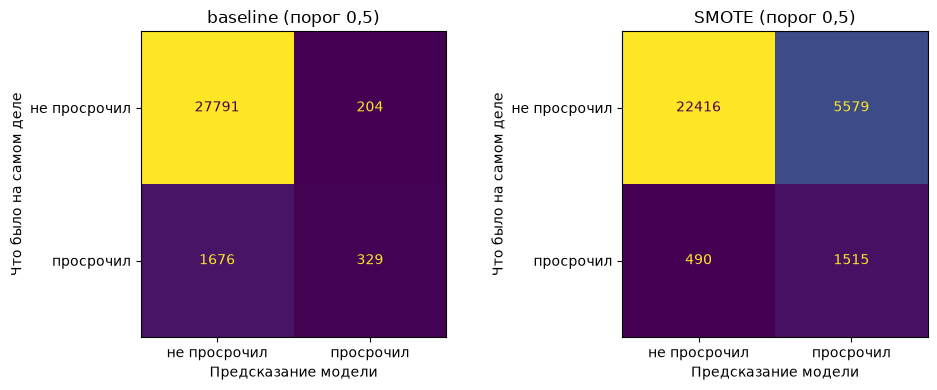

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["baseline", BEST]):
    pred = fitted[name].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, ax=ax, colorbar=False,
        display_labels=["не просрочил", "просрочил"]
    )
    ax.set_title(f"{name} (порог 0,5)")
    ax.set_xlabel("Предсказание модели")
    ax.set_ylabel("Что было на самом деле")
plt.tight_layout()
plt.show()

## Матрицы ошибок (порог 0,5)
Слева baseline, справа SMOTE. В тесте 2 005 настоящих должников и 27 995 клиентов без просрочки.

| | baseline | SMOTE | Что это значит в задаче |
|---|---|---|---|
| TN | 27 791 | 22 416 | Клиент без просрочки, модель верно его пропустила |
| FP | 204 | 5 579 | Хороший клиент, которому модель ошибочно предсказала просрочку (банк отказал бы зря, упущенная прибыль) |
| FN | 1 676 | 490 | Должник, которого модель не заметила (банк выдал бы кредит, который не вернут, прямой убыток) |
| TP | 329 | 1 515 | Должник, которого модель верно нашла |

Базовая модель пропускает 1 676 из 2 005 должников (84%) и почти не ошибается в хороших клиентах. SMOTE находит в 4,6 раза больше должников (1 515 против 329) и пропускает только 490, но ценой того, что около 5 600 хороших клиентов были бы отклонены. Для банка пропущенный должник обычно дороже упущенного хорошего клиента, поэтому такой обмен может быть оправдан.

In [10]:
oof = cross_val_predict(models[BEST], X_train, y_train, cv=5, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-12)
best_idx = np.argmax(f1s[:-1])
best_thr = thr[best_idx]
print(f"Порог по умолчанию: 0.5, подобранный порог: {best_thr:.3f}, F1 на валидации: {f1s[best_idx]:.3f}")

Порог по умолчанию: 0.5, подобранный порог: 0.743, F1 на валидации: 0.425


## Выбор порога классификации
Модель выдаёт вероятность просрочки, а решение «просрочит» принимается, если вероятность выше порога. По умолчанию порог равен 0,5, но он не обязан быть лучшим при дисбалансе. Порог подобран по out-of-fold предсказаниям на обучающей выборке (максимум F1): получилось 0,743 (F1 на валидации 0,425). Тестовая выборка при выборе не использовалась.

| Порог | Precision | Recall | F1 |
|---|---|---|---|
| 0,5 | 0,214 | 0,756 | 0,333 |
| 0,74 | 0,395 | 0,487 | 0,437 |

При повышении порога модель реже называет клиентов должниками: precision выросла почти вдвое (0,214 → 0,395), recall упал (0,756 → 0,487), F1 вырос с 0,333 до 0,437. Прирост F1 на тесте подтверждает выбор порога на валидации. Но F1 считает ошибки обоих видов одинаково важными. Если банку важнее не пропускать должников, чем не отказывать хорошим клиентам, порог можно оставить ниже. Окончательный выбор зависит от реальной цены двух видов ошибок, которой в задаче нет.

In [11]:
proba_test = fitted[BEST].predict_proba(X_test)[:, 1]
rows = []
for label, t in [("порог 0,5", 0.5), (f"порог {best_thr:.2f}", best_thr)]:
    pred = (proba_test >= t).astype(int)
    rows.append({
        "порог": label,
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
    })
pd.DataFrame(rows).set_index("порог").round(3)

,precision,recall,f1
порог,,,
"порог 0,5",0.214,0.756,0.333
порог 0.74,0.395,0.487,0.437


## Выбор порога
Порог выбран по out-of-fold предсказаниям на train (максимум F1), тестовая выборка при выборе не использовалась. (Дальше: чем подобранный порог отличается от 0,5 и что поменялось в precision и recall. Если банку важнее не пропускать должников, порог можно снижать дальше, ценой большего числа отказов хорошим клиентам.)

## Выводы
**1. Базовая модель.** Accuracy 0,937 выглядит отлично, но почти не лучше «всегда предсказывать отсутствие просрочки» (около 0,93). Recall равен 0,164: модель находит только 16% должников и пропускает 1 676 из 2 005. Accuracy при дисбалансе 14 : 1 вводит в заблуждение.

**2. Сравнение методов.** class_weight, undersampling и SMOTE одинаково повышают recall (0,164 → около 0,75) и F1 (0,257 → около 0,33). Цена: precision падает с 0,6 до 0,21, accuracy с 0,94 до 0,80. Между тремя методами различий практически нет (разница меньше разброса ±0,004).

**3. Улучшение не случайно.** Каждый метод лучше базы в 15 из 15 проверок кросс-валидации по F1 и recall, схема проверки одинакова, результаты на тесте совпадают с кросс-валидацией.

**4. Выбор метода.** Для дальнейшего анализа (матрицы ошибок, порог) использован SMOTE. Поскольку по качеству три метода эквивалентны, выбор сделан не по метрикам. С практической точки зрения class_weight проще и быстрее: он не создаёт синтетических данных и не требует дополнительной библиотеки.

**5. Что означает ROC-AUC.** Значение около 0,86 означает: если взять случайного должника и случайного клиента без просрочки, то в 86% пар у должника оценка риска окажется выше. ROC-AUC почти не изменился между методами (0,855 → 0,860), потому что методы меняют, где проходит граница решения, но мало меняют способность модели упорядочивать клиентов по риску. Поэтому качество ранжирования (PR-AUC около 0,38) остаётся почти неизменным.

**6. Порог.** Подобранный порог 0,74 вместо 0,5 повышает F1 (0,333 → 0,437) за счёт роста precision, но снижает recall. Выбор зависит от цены ошибок для банка.
